In [1]:
# 导入 Gymnasium 环境库（新版 gym，替代旧版 gym）
import gymnasium as gym
# 导入 PyTorch，用于张量运算、神经网络和自动求导
import torch
# 导入 PyTorch 神经网络模块，用于搭建策略网络
import torch.nn as nn
# 导入 Adam 优化器，用于自动更新策略网络参数
import torch.optim as optim
# 导入分类分布，用于根据动作概率采样，并自动计算 log_prob
from torch.distributions import Categorical
# 导入 Matplotlib，用于绘制奖励曲线
import matplotlib.pyplot as plt


# 创建 CartPole-v1 环境
# v1 的最大步数为 500，v0 是 200，所以 v1 更难一点
env = gym.make('CartPole-v1')

# 状态维度：4
# [小车位置, 小车速度, 杆角度, 杆角速度]
n_state = env.observation_space.shape[0]

# 动作数量：2
# 0 表示向左推，1 表示向右推
n_action = env.action_space.n


class PolicyNet(nn.Module):
    """
    策略网络：把状态映射成动作 logits。

    这里没有加隐藏层，因为 CartPole 比较简单，
    线性策略已经能学到不错的效果。
    如果训练不稳定，可以改成带隐藏层的多层网络。
    """
    def __init__(self, n_state, n_action):
        super().__init__()
        self.fc = nn.Linear(n_state, n_action)

    def forward(self, state):
        # 输出 logits，不要在这里做 softmax
        # Categorical(logits=...) 内部会自动处理 softmax
        return self.fc(state)


def run_episode(env, policy):
    """
    用当前策略跑完一个完整 episode。

    REINFORCE 是蒙特卡洛策略梯度算法，
    必须跑完整个 episode 后才能计算回报并更新参数。

    返回:
        total_reward: 该 episode 的累计奖励
        log_probs: 每一步动作的对数概率列表
        rewards: 每一步的奖励列表
    """
    # 重置环境，获取初始状态
    state, _ = env.reset()

    log_probs = []     # 记录每一步动作的对数概率
    rewards = []       # 记录每一步的奖励
    total_reward = 0
    terminated = False
    truncated = False

    while not (terminated or truncated):
        # 将 numpy 数组转为 PyTorch 浮点张量
        state = torch.from_numpy(state).float()

        # 策略网络输出动作 logits
        logits = policy(state)

        # 根据 logits 构造分类分布
        dist = Categorical(logits=logits)

        # 从策略分布中采样动作
        action = dist.sample()

        # 记录该动作的对数概率，后续用于策略梯度更新
        log_probs.append(dist.log_prob(action))

        # 执行动作
        state, reward, terminated, truncated, _ = env.step(action.item())

        rewards.append(reward)
        total_reward += reward

    return total_reward, log_probs, rewards


def discount_rewards(rewards, gamma):
    """
    计算折扣回报 G_t = r_t + gamma * G_{t+1}。

    从最后一步往前递推计算，这样每一步的回报都包含未来奖励。
    gamma 越接近 1，越重视远期奖励。
    """
    returns = []
    G = 0.0
    for r in reversed(rewards):
        G = r + gamma * G
        returns.insert(0, G)
    return returns


def normalize_returns(returns):
    """
    对回报做标准化：减均值、除标准差。

    这一步是 REINFORCE 常用的方差降低技巧。
    回报幅度变化很大时，标准化能让梯度更新更稳定。
    """
    returns = torch.tensor(returns, dtype=torch.float32)
    mean = returns.mean()
    std = returns.std()

    # 防止标准差过小导致除零
    if std < 1e-8:
        return returns - mean

    return (returns - mean) / std

Episode 50: reward=20.0, last_50_avg=19.58
Episode 100: reward=14.0, last_50_avg=23.06
Episode 150: reward=16.0, last_50_avg=25.68
Episode 200: reward=29.0, last_50_avg=30.00
Episode 250: reward=94.0, last_50_avg=44.44
Episode 300: reward=28.0, last_50_avg=69.82
Episode 350: reward=24.0, last_50_avg=125.80
Episode 400: reward=168.0, last_50_avg=161.10
Episode 450: reward=325.0, last_50_avg=195.62
Episode 500: reward=155.0, last_50_avg=229.06
Episode 550: reward=138.0, last_50_avg=278.30
Episode 600: reward=500.0, last_50_avg=323.36
Episode 650: reward=99.0, last_50_avg=261.00
Episode 700: reward=231.0, last_50_avg=264.10
Episode 750: reward=500.0, last_50_avg=375.10
Episode 800: reward=280.0, last_50_avg=378.58
Episode 850: reward=423.0, last_50_avg=378.56
Episode 900: reward=334.0, last_50_avg=384.44
Episode 950: reward=346.0, last_50_avg=378.84
Episode 1000: reward=500.0, last_50_avg=429.82
Average total reward over 1000 episode: 218.81


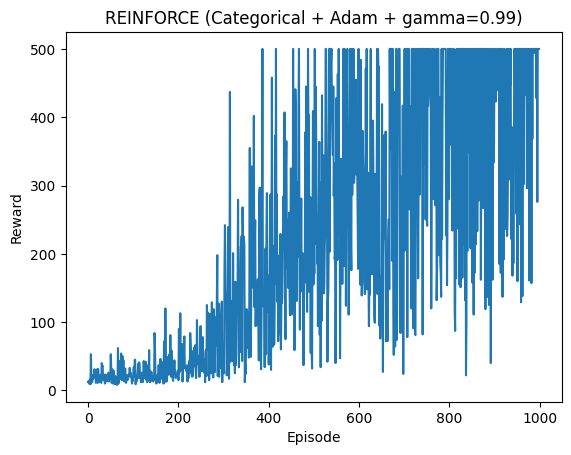

In [2]:
# ==================== 超参数 ====================

n_episode = 1000     # 训练轮数
lr = 0.01            # 学习率
gamma = 0.99         # 折扣因子，越接近 1 越重视远期奖励

# 创建策略网络和优化器
policy = PolicyNet(n_state, n_action)
optimizer = optim.Adam(policy.parameters(), lr=lr)

total_rewards = []   # 记录每轮奖励

# ==================== 训练循环 ====================

for episode in range(n_episode):
    # 用当前策略采样一个完整 episode
    total_reward, log_probs, rewards = run_episode(env, policy)

    # 计算每一步的折扣回报
    returns = discount_rewards(rewards, gamma)

    # 对回报做标准化，降低梯度方差
    returns = normalize_returns(returns)

    # REINFORCE 损失：
    # L = -sum(log_prob(a_t|s_t) * G_t)
    # 取负号是因为 PyTorch 默认做梯度下降，
    # 而策略梯度需要梯度上升。
    policy_loss = -torch.sum(
        torch.stack(log_probs) * returns
    )

    # 清空旧梯度
    optimizer.zero_grad()

    # 反向传播，自动计算策略梯度
    policy_loss.backward()

    # 梯度裁剪，防止梯度爆炸导致训练不稳定
    torch.nn.utils.clip_grad_norm_(policy.parameters(), max_norm=0.5)

    # 更新策略网络参数
    optimizer.step()

    total_rewards.append(total_reward)

    # 每 50 轮打印一次最近平均奖励，方便观察训练进度
    if (episode + 1) % 50 == 0:
        avg = sum(total_rewards[-50:]) / 50
        print(f'Episode {episode + 1}: reward={total_reward}, '
              f'last_50_avg={avg:.2f}')

    # 早停条件：最近 100 轮平均奖励达到 495 就停止
    # CartPole-v1 满分是 500，495 已经非常接近最优
    if len(total_rewards) >= 100 and sum(total_rewards[-100:]) >= 49500:
        print(f'Training finished at episode {episode + 1}')
        break

print(f'Average total reward over {len(total_rewards)} episode: '
      f'{sum(total_rewards) / len(total_rewards):.2f}')

# 绘制训练奖励曲线
plt.plot(total_rewards)
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.title('REINFORCE (Categorical + Adam + gamma=0.99)')
plt.show()

In [3]:
# ==================== 评估 ====================

n_episode_eval = 100
total_rewards_eval = []

for episode in range(n_episode_eval):
    total_reward, _, _ = run_episode(env, policy)
    total_rewards_eval.append(total_reward)

print(f'Average eval reward over {n_episode_eval} episode: '
      f'{sum(total_rewards_eval) / n_episode_eval:.2f}')

Average eval reward over 100 episode: 429.49
